In [175]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

RANDOM_STATE = 42
LEARNING_RATE = 0.05
N_ITERATIONS = 1000
THRESHOLD = 0.5
np.random.seed(RANDOM_STATE)

In [176]:
def load_diabetes_data():
    url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
    columns = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness", "Insulin",
               "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"]
    try:
        data = pd.read_csv(url, header=None, names=columns)
    except Exception as exc:
        raise RuntimeError("Could not download the lab dataset. Check your internet connection.") from exc
    if data.shape[1] != len(columns) or not set(data["Outcome"].unique()).issubset({0, 1}):
        raise ValueError("Unexpected dataset format or non-binary outcome values.")
    return data


df = load_diabetes_data()
print("Dataset shape:", df.shape)
display(df.head())
print("Class distribution:")
print(df["Outcome"].value_counts().sort_index())

Dataset shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Class distribution:
Outcome
0    500
1    268
Name: count, dtype: int64


In [177]:
zero_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

print((df[zero_columns] == 0).sum())

Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


In [178]:
feature_columns = [column for column in df.columns if column != "Outcome"]
X = df[feature_columns]
y = df["Outcome"].astype(int)

X_train_raw, X_val_raw, y_train_series, y_val_series = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

y_train = y_train_series.to_numpy(dtype=int)
y_val = y_val_series.to_numpy(dtype=int)

print("Training samples:", len(y_train))
print("Validation samples:", len(y_val))
print("Training class counts:", np.bincount(y_train))
print("Validation class counts:", np.bincount(y_val))

Training samples: 614
Validation samples: 154
Training class counts: [400 214]
Validation class counts: [100  54]


In [179]:
zero_as_missing = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

X_train_clean = X_train_raw.copy()
X_val_clean = X_val_raw.copy()
X_train_clean[zero_as_missing] = X_train_clean[zero_as_missing].replace(0, np.nan)
X_val_clean[zero_as_missing] = X_val_clean[zero_as_missing].replace(0, np.nan)

imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()
X_train = scaler.fit_transform(imputer.fit_transform(X_train_clean))
X_val = scaler.transform(imputer.transform(X_val_clean))

print("Processed training features:", X_train.shape)
print("Processed validation features:", X_val.shape)
assert np.isfinite(X_train).all() and np.isfinite(X_val).all()

Processed training features: (614, 8)
Processed validation features: (154, 8)


In [180]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))


def log_loss(y_true, y_pred):
    epsilon = 1e-15
    y_pred = np.clip(y_pred, epsilon, 1 - epsilon)
    return -np.mean(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))


def misclassification_error(y_true, y_pred_probs, threshold=0.5):
    y_pred_labels = (y_pred_probs >= threshold).astype(int)
    return np.mean(y_pred_labels != y_true)

In [181]:
def train_logistic_regression(X_train, y_train, X_val, y_val,
                              learning_rate=0.05, n_iterations=1000):
    X_train_b = np.column_stack((np.ones(X_train.shape[0]), X_train))
    X_val_b = np.column_stack((np.ones(X_val.shape[0]), X_val))
    weights = np.zeros(X_train_b.shape[1], dtype=float)
    losses, errors = [], []

    for _ in range(n_iterations):
        p_train = sigmoid(X_train_b @ weights)
        gradient = X_train_b.T @ (p_train - y_train) / len(y_train)
        weights -= learning_rate * gradient
        p_train = sigmoid(X_train_b @ weights)
        p_val = sigmoid(X_val_b @ weights)
        losses.append((log_loss(y_train, p_train), log_loss(y_val, p_val)))
        errors.append((misclassification_error(y_train, p_train), misclassification_error(y_val, p_val)))

    history = pd.DataFrame(np.column_stack((losses, errors)), columns=[
        "Train Log Loss", "Validation Log Loss", "Train Misclassification", "Validation Misclassification"
    ])
    history.insert(0, "Iteration", np.arange(1, n_iterations + 1))
    return weights, history


def logistic_predict_proba(X, weights):
    X_b = np.column_stack((np.ones(X.shape[0]), X))
    return sigmoid(X_b @ weights)


def logistic_predict(X, weights, threshold=0.5):
    return (logistic_predict_proba(X, weights) >= threshold).astype(int)

In [182]:
lr_weights, lr_history = train_logistic_regression(
    X_train, y_train, X_val, y_val,
    learning_rate=LEARNING_RATE,
    n_iterations=N_ITERATIONS
)

lr_train_probs = logistic_predict_proba(X_train, lr_weights)
lr_val_probs = logistic_predict_proba(X_val, lr_weights)

print("Final weights (intercept first):", np.round(lr_weights, 5))
print("Final training log loss:", round(log_loss(y_train, lr_train_probs), 5))
print("Final validation log loss:", round(log_loss(y_val, lr_val_probs), 5))
display(lr_history)

Final weights (intercept first): [-0.86859  0.37257  1.17774 -0.03862  0.03945 -0.05814  0.67581  0.23424
  0.15048]
Final training log loss: 0.45316
Final validation log loss: 0.51396


,Iteration,Train Log Loss,Validation Log Loss,Train Misclassification,Validation Misclassification
0,1,0.684752,0.686148,0.254072,0.298701
1,2,0.676782,0.679523,0.254072,0.298701
2,3,0.669215,0.673250,0.254072,0.298701
3,4,0.662026,0.667310,0.254072,0.298701
4,5,0.655194,0.661682,0.254072,0.298701
...,...,...,...,...,...
995,996,0.453158,0.513954,0.203583,0.305195
996,997,0.453157,0.513956,0.203583,0.305195
997,998,0.453157,0.513957,0.203583,0.305195
998,999,0.453156,0.513959,0.203583,0.305195


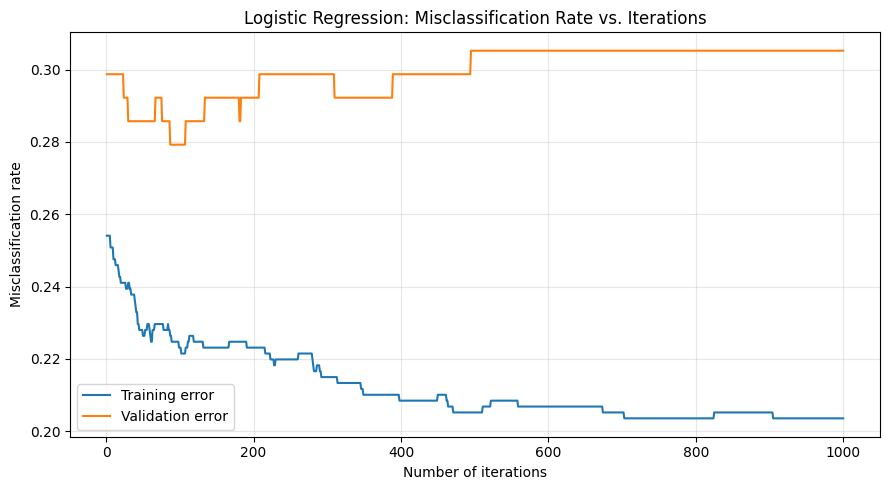

In [183]:
plt.figure(figsize=(9, 5))
plt.plot(lr_history["Iteration"], lr_history["Train Misclassification"], label="Training error")
plt.plot(lr_history["Iteration"], lr_history["Validation Misclassification"], label="Validation error")
plt.xlabel("Number of iterations")
plt.ylabel("Misclassification rate")
plt.title("Logistic Regression: Misclassification Rate vs. Iterations")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

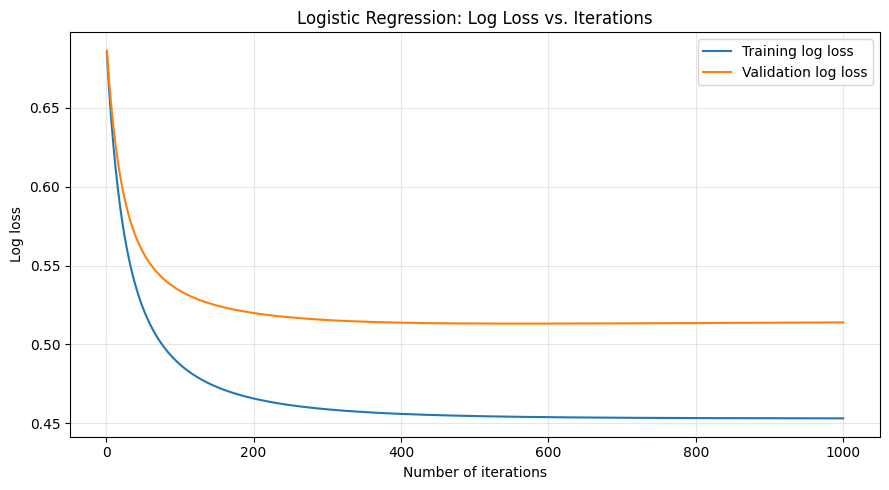

In [184]:
plt.figure(figsize=(9, 5))
plt.plot(lr_history["Iteration"], lr_history["Train Log Loss"], label="Training log loss")
plt.plot(lr_history["Iteration"], lr_history["Validation Log Loss"], label="Validation log loss")
plt.xlabel("Number of iterations")
plt.ylabel("Log loss")
plt.title("Logistic Regression: Log Loss vs. Iterations")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [185]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

def evaluate_model(model_name, split_name, y_true, y_prob, threshold=0.5):

    predictions = (np.asarray(y_prob) >= threshold).astype(int)

    cm = confusion_matrix(y_true, predictions, labels=[0, 1])

    results = {
        "Model": model_name,
        "Split": split_name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions, zero_division=0),
        "Recall": recall_score(y_true, predictions, zero_division=0),
        "F1 Score": f1_score(y_true, predictions, zero_division=0)
    }
    fig, ax = plt.subplots(figsize=(6, 5))

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Diabetes", "Diabetes"]
    )

    disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")

    ax.set_title(f"{model_name} - {split_name} Confusion Matrix")
    plt.tight_layout()
    plt.show()
    metric_names = ["Accuracy", "Precision", "Recall", "F1 Score"]
    metric_values = [results[name] for name in metric_names]

    fig, ax = plt.subplots(figsize=(8, 5))

    bars = ax.bar(metric_names, metric_values, width=0.6)

    ax.bar_label(bars, fmt="%.3f", padding=3)

    ax.set_ylim(0, 1.1)
    ax.set_ylabel("Score")
    ax.set_title(f"{model_name} - {split_name} Performance")
    ax.grid(axis="y", alpha=0.3)

    plt.tight_layout()
    plt.show()

    return results


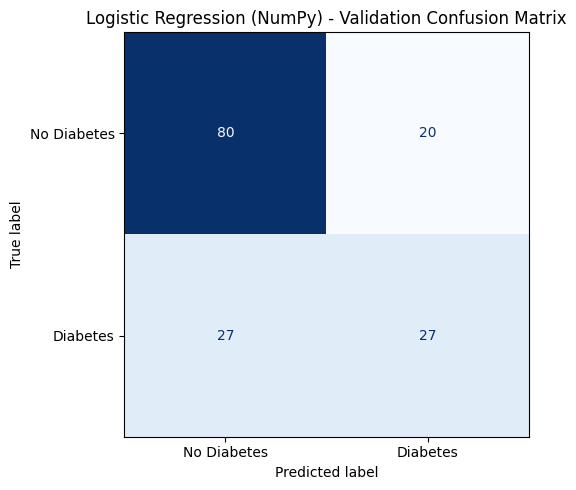

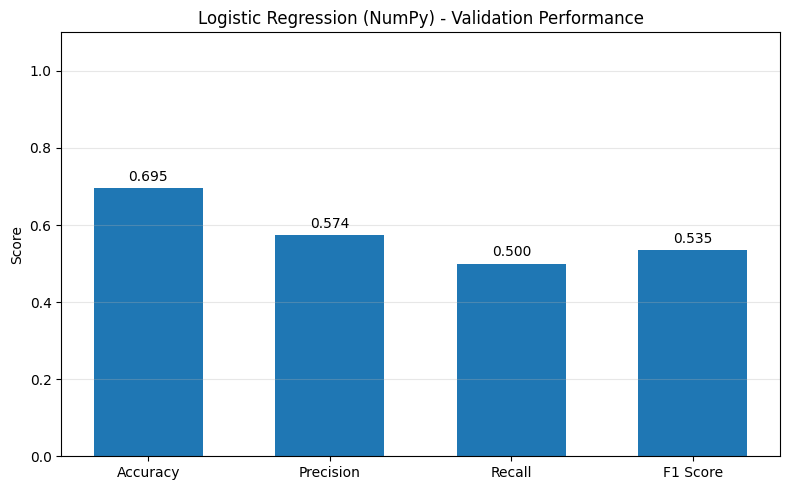

In [186]:
# lr_train_metrics = evaluate_model("Logistic Regression (NumPy)", "Train", y_train, lr_train_probs, THRESHOLD)
lr_val_metrics = evaluate_model("Logistic Regression (NumPy)", "Validation", y_val, lr_val_probs, THRESHOLD)

In [187]:
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)

nb_train_probs = nb_model.predict_proba(X_train)[:, 1]
nb_val_probs = nb_model.predict_proba(X_val)[:, 1]

print("GaussianNB trained successfully")
print("Class labels:", nb_model.classes_)
print("Training log loss:", round(log_loss(y_train, nb_train_probs), 5))
print("Validation log loss:", round(log_loss(y_val, nb_val_probs), 5))

GaussianNB trained successfully
Class labels: [0 1]
Training log loss: 0.63657
Validation log loss: 0.944


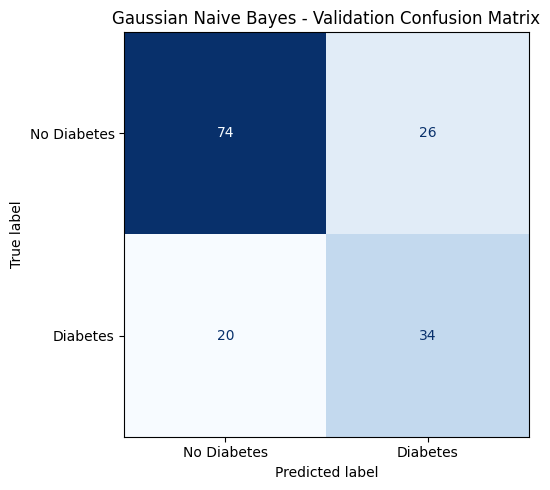

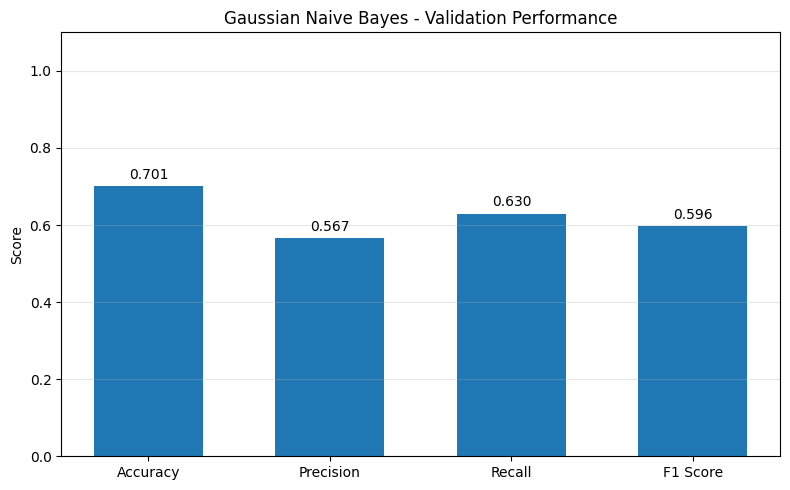

In [188]:
# nb_train_metrics = evaluate_model("Gaussian Naive Bayes", "Train", y_train, nb_train_probs, THRESHOLD)
nb_val_metrics = evaluate_model("Gaussian Naive Bayes", "Validation", y_val, nb_val_probs, THRESHOLD)

In [189]:
comparison = pd.DataFrame([
    lr_val_metrics,
    nb_val_metrics
])

display(comparison.round(4))

,Model,Split,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression (NumPy),Validation,0.6948,0.5745,0.5000,0.5347
1,Gaussian Naive Bayes,Validation,0.7013,0.5667,0.6296,0.5965
